In [1]:
!pip install scikit-optimize

In [1]:
import pandas as pd
import numpy as np
import regex as re
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error

from keras.models import Sequential
from keras.layers import Dense, Input
from keras.optimizers import Adam
from keras.activations import tanh
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.svm import SVR
#from skopt import BayesSearchCV


In [2]:
#data_cacak = pd.read_csv("/content/drive/MyDrive/datasets/GRIDouble/Data_Cacak.csv")
#data_kraljevo = pd.read_csv('/content/drive/MyDrive/datasets/GRIDouble/Data_Kraljevo.csv')
data_cacak = pd.read_csv(r"C:\Users\sachl\Downloads\GRIDouble-main\GRIDouble-main\data\Data_Cacak.csv")
data_kraljevo = pd.read_csv(r"C:\Users\sachl\Downloads\GRIDouble-main\GRIDouble-main\data\Data_Kraljevo.csv")

In [3]:
display(data_cacak)

,Datetime,AirTemperature,CloudOpacity,DHI,DNI,EBH,GHI,Production - Location 1,Production - Location 2,Production - Location 3
0,11/22/2022 14:00,8.7,59,117,0.0,0,117,11.705333,12.694917,16.355417
1,11/22/2022 15:00,8.9,62,62,0.0,0,62,1.309583,8.262333,1.812333
2,11/22/2022 16:00,9.2,57,15,7.0,1,16,0.000000,0.930667,0.000000
3,11/22/2022 17:00,8.9,81,0,0.0,0,0,0.000000,0.000000,0.000000
4,11/22/2022 18:00,8.9,91,0,0.0,0,0,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...
8269,11/2/2023 3:00,9.9,74,0,0.0,0,0,0.000000,0.000000,0.000000
8270,11/2/2023 4:00,9.8,76,0,0.0,0,0,0.000000,0.000000,0.000000
8271,11/2/2023 5:00,9.8,74,0,0.0,0,0,0.000000,0.000000,0.000000
8272,11/2/2023 6:00,9.7,53,0,0.0,0,0,5.377333,0.000000,3.346583


In [5]:
display(data_kraljevo)

,Datetime,AirTemperature,CloudOpacity,DHI,DNI,EBH,GHI,Production - Kraljevo Location
0,11/22/2022 14:00,6.1,91,68,1.1,1,69,31.246833
1,11/22/2022 15:00,5.9,71,55,4.5,1,56,3.480250
2,11/22/2022 16:00,5.2,100,19,1.5,0,19,0.000000
3,11/22/2022 17:00,5.1,79,0,0.0,0,0,0.000000
4,11/22/2022 18:00,5.0,60,0,0.0,0,0,0.000000
...,...,...,...,...,...,...,...,...
8269,11-02-23 03:00,10.4,92,0,0.0,0,0,0.000000
8270,11-02-23 04:00,9.9,97,0,0.0,0,0,0.000000
8271,11-02-23 05:00,9.5,100,0,0.0,0,0,0.000000
8272,11-02-23 06:00,9.7,99,0,0.0,0,0,14.780000


In [6]:
print(data_kraljevo['Datetime'].iloc[6777])

09-01-23 00:00


In [7]:
def convert_date_format(date_str):
    # Replace the hyphens with slashes
    date_str = re.sub(r"(\d{2})-(\d{2})-(\d{2})", r"\1/\2/20\3", date_str)
    return date_str

In [8]:
# Apply to the entire column
data_kraljevo['Datetime'] = data_kraljevo['Datetime'].apply(convert_date_format)

In [9]:
data_kraljevo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8274 entries, 0 to 8273
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Datetime                        8274 non-null   object 
 1   AirTemperature                  8274 non-null   float64
 2   CloudOpacity                    8274 non-null   int64  
 3   DHI                             8274 non-null   int64  
 4   DNI                             8274 non-null   float64
 5   EBH                             8274 non-null   int64  
 6   GHI                             8274 non-null   int64  
 7   Production - Kraljevo Location  8274 non-null   float64
dtypes: float64(3), int64(4), object(1)
memory usage: 517.3+ KB


In [10]:
data_cacak.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8274 entries, 0 to 8273
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Datetime                 8274 non-null   object 
 1   AirTemperature           8274 non-null   float64
 2   CloudOpacity             8274 non-null   int64  
 3   DHI                      8274 non-null   int64  
 4   DNI                      8274 non-null   float64
 5   EBH                      8274 non-null   int64  
 6   GHI                      8274 non-null   int64  
 7   Production - Location 1  8274 non-null   float64
 8   Production - Location 2  8274 non-null   float64
 9   Production - Location 3  8274 non-null   float64
dtypes: float64(5), int64(4), object(1)
memory usage: 646.5+ KB


In [11]:
# Convert 'Datetime' to datetime format
data_cacak['Datetime'] = pd.to_datetime(data_cacak['Datetime'])
data_kraljevo['Datetime'] = pd.to_datetime(data_kraljevo['Datetime'])

In [12]:
data_kraljevo

,Datetime,AirTemperature,CloudOpacity,DHI,DNI,EBH,GHI,Production - Kraljevo Location
0,2022-11-22 14:00:00,6.1,91,68,1.1,1,69,31.246833
1,2022-11-22 15:00:00,5.9,71,55,4.5,1,56,3.480250
2,2022-11-22 16:00:00,5.2,100,19,1.5,0,19,0.000000
3,2022-11-22 17:00:00,5.1,79,0,0.0,0,0,0.000000
4,2022-11-22 18:00:00,5.0,60,0,0.0,0,0,0.000000
...,...,...,...,...,...,...,...,...
8269,2023-11-02 03:00:00,10.4,92,0,0.0,0,0,0.000000
8270,2023-11-02 04:00:00,9.9,97,0,0.0,0,0,0.000000
8271,2023-11-02 05:00:00,9.5,100,0,0.0,0,0,0.000000
8272,2023-11-02 06:00:00,9.7,99,0,0.0,0,0,14.780000


In [13]:
# Check for missing values
print(data_cacak.isnull().sum())
print(data_kraljevo.isnull().sum())

Datetime                   0
AirTemperature             0
CloudOpacity               0
DHI                        0
DNI                        0
EBH                        0
GHI                        0
Production - Location 1    0
Production - Location 2    0
Production - Location 3    0
dtype: int64
Datetime                          0
AirTemperature                    0
CloudOpacity                      0
DHI                               0
DNI                               0
EBH                               0
GHI                               0
Production - Kraljevo Location    0
dtype: int64


In [14]:
# extracting the year, hour and date
data_cacak['Year'] = data_cacak['Datetime'].dt.year
data_cacak['Month'] = data_cacak['Datetime'].dt.month
data_cacak['Hour'] = data_cacak['Datetime'].dt.hour
data_cacak['Day'] = data_cacak['Datetime'].dt.day

data_kraljevo['Year'] = data_kraljevo['Datetime'].dt.year
data_kraljevo['Month'] = data_kraljevo['Datetime'].dt.month
data_kraljevo['Hour'] = data_kraljevo['Datetime'].dt.hour
data_kraljevo['Day'] = data_kraljevo['Datetime'].dt.day

In [15]:
data_cacak.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8274 entries, 0 to 8273
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Datetime                 8274 non-null   datetime64[ns]
 1   AirTemperature           8274 non-null   float64       
 2   CloudOpacity             8274 non-null   int64         
 3   DHI                      8274 non-null   int64         
 4   DNI                      8274 non-null   float64       
 5   EBH                      8274 non-null   int64         
 6   GHI                      8274 non-null   int64         
 7   Production - Location 1  8274 non-null   float64       
 8   Production - Location 2  8274 non-null   float64       
 9   Production - Location 3  8274 non-null   float64       
 10  Year                     8274 non-null   int32         
 11  Month                    8274 non-null   int32         
 12  Hour                     8274 non-

In [16]:
# Sum the production values from the three locations
data_cacak['Total_Production'] = data_cacak['Production - Location 1'] + data_cacak['Production - Location 2'] + data_cacak['Production - Location 3']

In [17]:
# Select features
features = ['AirTemperature', 'CloudOpacity', 'DHI', 'DNI', 'EBH', 'GHI']

# Define targets
target_cacak = 'Production - Location 2'  # You can choose other locations if preferred
target_kraljevo = 'Production - Kraljevo Location'


In [18]:
# Prepare feature matrices and target vectors
X_cacak = data_cacak[features]
y_cacak = data_cacak[target_cacak]

X_kraljevo = data_kraljevo[features]
y_kraljevo = data_kraljevo[target_kraljevo]

In [19]:
# Split data for Cacak
X_train_cacak, X_temp_cacak, y_train_cacak, y_temp_cacak = train_test_split(X_cacak, y_cacak, test_size=0.2, random_state=42)

X_val_cacak, X_test_cacak, y_val_cacak, y_test_cacak = train_test_split(X_temp_cacak, y_temp_cacak, test_size = 0.5, random_state=42)


In [20]:
# train, val, test shape

print(X_train_cacak.shape, y_train_cacak.shape)
print(X_test_cacak.shape, y_test_cacak.shape)
print(X_val_cacak.shape, y_val_cacak.shape)

(6619, 6) (6619,)
(828, 6) (828,)
(827, 6) (827,)


# Models (cacak data)

## ANN

In [330]:
# Build the ANN model for cacak

model = Sequential()
input_dim=X_train_cacak.shape[1]

model.add(Input(shape=(input_dim,)))
model.add(Dense(units=20, activation='tanh'))
model.add(Dense(units=20, activation='tanh'))
model.add(Dense(units=10, activation='tanh'))
model.add(Dense(units=1, activation='linear'))

model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=0.001), metrics=['mae'])
model.summary()

Model: "sequential_34"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_86 (Dense)                     │ (None, 20)                  │             140 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_87 (Dense)                     │ (None, 20)                  │             420 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_88 (Dense)                     │ (None, 10)                  │             210 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_89 (Dense)                     │ (None, 1)                   │              11 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 781 (3.05 KB)

 Trainable params: 781 (3.05 KB)

 Non-trainable params: 0 (0.00 B)

In [331]:
# Train the model
history = model.fit(X_train_cacak, y_train_cacak, validation_data=(X_val_cacak, y_val_cacak), epochs=100, batch_size=32)

Epoch 1/100
207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 2436.4307 - mae: 25.0397 - val_loss: 2295.9104 - val_mae: 23.8354
Epoch 2/100
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 2262.0891 - mae: 23.2114 - val_loss: 2186.2800 - val_mae: 22.8359
Epoch 3/100
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 2092.1704 - mae: 22.1157 - val_loss: 2092.3735 - val_mae: 22.2211
Epoch 4/100
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1998.6145 - mae: 21.1411 - val_loss: 2006.1307 - val_mae: 21.7339
Epoch 5/100
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1991.1313 - mae: 21.0299 - val_loss: 1924.4087 - val_mae: 21.1154
Epoch 6/100
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1876.6765 - mae: 20.3873 - val_loss: 1847.8029 - val_mae: 20.5244
Epoch 7/100
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1877.9138 - mae: 20.3522 - val_loss: 1775.9628 - val_mae: 20.0085
Epoch 8/100
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1658.1146 - mae: 18.9810 - val_loss: 1706.7684 - v

In [333]:
# Evaluate ANN performance
y_power_pred_ann = model.predict(X_test_cacak)
r2_ann = r2_score(y_test_cacak, y_power_pred_ann)
mae_ann = mean_absolute_error(y_test_cacak, y_power_pred_ann)
rmse_ann = np.sqrt(mean_squared_error(y_test_cacak, y_power_pred_ann))
mse_ann = mean_squared_error(y_test_cacak, y_power_pred_ann)

print(f"ANN: R2: {r2_ann}, MAE: {mae_ann}, RMSE: {rmse_ann}, MSE: {mse_ann}")

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
ANN: R2: 0.8941696680156278, MAE: 7.923312885883467, RMSE: 14.518553874802372, MSE: 210.78840661553897


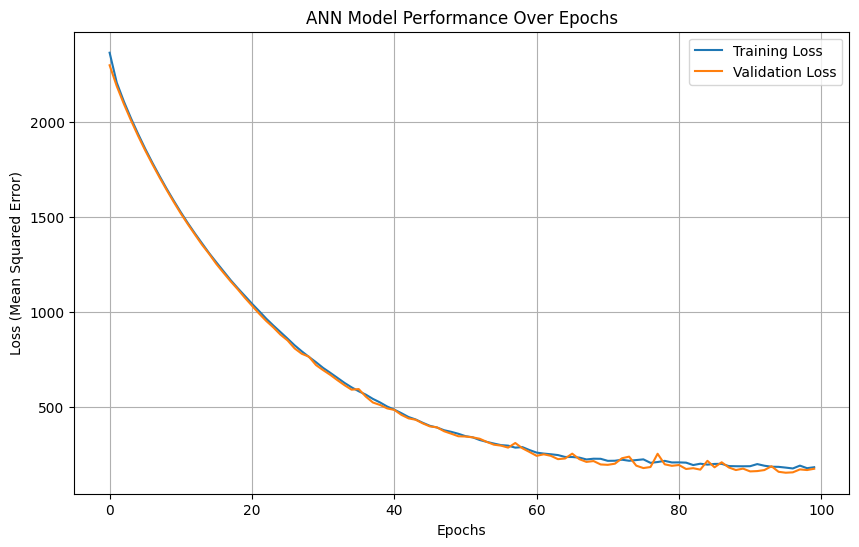

In [334]:
# Plot the training loss and validation loss
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

# Adding titles and labels
plt.title('ANN Model Performance Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (Mean Squared Error)')
plt.legend()
plt.grid(True)
plt.show()

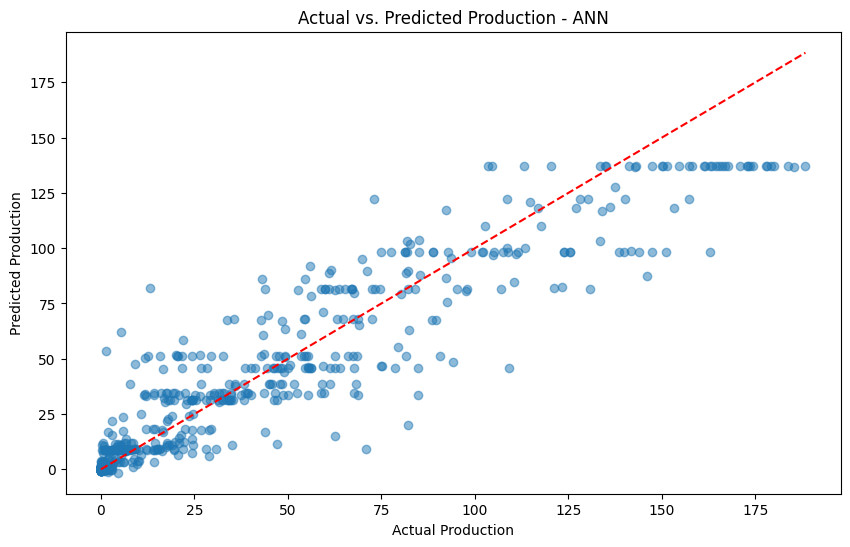

In [335]:
# Plot actual vs. predicted values for test data
plt.figure(figsize=(10, 6))
plt.scatter(y_test_cacak, y_power_pred_ann, alpha=0.5)
plt.xlabel('Actual Production')
plt.ylabel('Predicted Production')
plt.title('Actual vs. Predicted Production - ANN')
plt.plot([min(y_test_cacak), max(y_test_cacak)], [min(y_test_cacak), max(y_test_cacak)], color='red', linestyle='--')
plt.show()

## Sparse Neural Network

In [21]:
!pip install tensorflow-model-optimization

In [62]:
!pip install keras==3.0

  Using cached keras-3.0.0-py3-none-any.whl.metadata (5.3 kB)
Using cached keras-3.0.0-py3-none-any.whl (997 kB)
  Attempting uninstall: keras
    Found existing installation: keras 2.15.0
    Uninstalling keras-2.15.0:
      Successfully uninstalled keras-2.15.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.15.0 requires keras<2.16,>=2.15.0, but you have keras 3.0.0 which is incompatible.
tf-keras 2.17.0 requires tensorflow<2.18,>=2.17, but you have tensorflow 2.15.0 which is incompatible.


In [ ]:
!pip install tensorflow==2.15.0

In [24]:
#import tensorflow as tf
#from keras import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import tensorflow_model_optimization as tfmot

ModuleNotFoundError: No module named 'tf_keras'

In [30]:
print(tf.__version__)
print(keras.__version__)

2.15.0


AttributeError: module 'tensorflow.keras' has no attribute '__version__'

In [23]:
# Define pruning schedule
pruning_schedule = tfmot.sparsity.keras.PolynomialDecay(
    initial_sparsity=0.0,
    final_sparsity=0.5,
    begin_step=0,
    end_step=1000
)


In [39]:

# Function to create a pruned Sequential model
def create_pruned_ann_model(input_dim):
    # Create a Sequential model
    model = Sequential([
        Dense(20, activation='tanh', input_shape=(input_dim,)),
        Dense(10, activation='tanh'),
        Dense(10, activation='tanh'),
        Dense(1, activation='linear')
    ])

    # Apply pruning to the entire Sequential model
    pruned_model = tfmot.sparsity.keras.prune_low_magnitude(model, pruning_schedule=pruning_schedule)

    return pruned_model

# Create and compile the pruned model
model = create_pruned_ann_model(X_train_cacak.shape[1])
model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=0.001), metrics=['mae'])


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:73: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


ValueError: `prune_low_magnitude` can only prune an object of the following types: keras.models.Sequential, keras functional model, keras.layers.Layer, list of keras.layers.Layer. You passed an object of type: Sequential.

In [ ]:
# Train the pruned model
callbacks_list = [tfmot.sparsity.keras.UpdatePruningStep()]

history_pruned = pruned_model.fit(
    X_train_cacak, y_train_cacak,
    validation_data=(X_val_cacak, y_val_cacak),
    epochs=100,
    batch_size=32,
    callbacks=callbacks_list
)

In [ ]:
# Evaluate pruned performance
y_power_pred_pruned = pruned_model.predict(X_test_cacak)
r2_pruned = r2_score(y_test_cacak, y_power_pred_pruned)
mae_pruned = mean_absolute_error(y_test_cacak, y_power_pred_pruned)
rmse_pruned = np.sqrt(mean_squared_error(y_test_cacak, y_power_pred_pruned))
mse_pruned = mean_squared_error(y_test_cacak, y_power_pred_pruned)

print(f"SVM: R2: {r2_pruned}, MAE: {mae_pruned}, RMSE: {rmse_pruned}, MSE: {mse_pruned}")

## SVM

In [213]:
# Define the parameter search space
param_space = {
    'C': (0.001, 1000.0, 'uniform'),  # Box constraint
    'gamma': (0.001, 1000.0, 'uniform'),  # Kernel scale
    'epsilon': (0.016814, 1681.4152, 'uniform'),  # Epsilon
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid']
}

In [214]:
# Define the SVM model
svm = SVR()

In [215]:
# Bayesian optimization using BayesSearchCV
opt = BayesSearchCV(
    svm,
    param_space,
    n_iter=50,  # Number of iterations for optimization
    cv=5,       # Number of cross-validation folds
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=42
)

In [217]:
# Fit the model
opt.fit(X_train_cacak, y_train_cacak)

/usr/local/lib/python3.10/dist-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()
/usr/local/lib/python3.10/dist-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()


BayesSearchCV(cv=5, estimator=SVR(), n_jobs=-1, random_state=42,
              scoring='neg_mean_squared_error',
              search_spaces={'C': (0.001, 1000.0, 'uniform'),
                             'epsilon': (0.016814, 1681.4152, 'uniform'),
                             'gamma': (0.001, 1000.0, 'uniform'),
                             'kernel': ['linear', 'poly', 'rbf', 'sigmoid']})

In [218]:
# Best parameters
print("Best Parameters:", opt.best_params_)

Best Parameters: OrderedDict([('C', 1000.0), ('epsilon', 0.016814), ('gamma', 0.001), ('kernel', 'rbf')])


In [219]:
# Train the SVM model with the best parameters
best_svm = opt.best_estimator_

In [220]:
# Evaluate svm performance
y_power_pred_svm = best_svm.predict(X_test_cacak)
r2_svm = r2_score(y_test_cacak, y_power_pred_svm)
mae_svm = mean_absolute_error(y_test_cacak, y_power_pred_svm)
rmse_svm = np.sqrt(mean_squared_error(y_test_cacak, y_power_pred_svm))
mse_svm = mean_squared_error(y_test_cacak, y_power_pred_svm)

print(f"SVM: R2: {r2_svm}, MAE: {mae_svm}, RMSE: {rmse_svm}, MSE: {mse_svm}")

SVM: R2: 0.8746738717679995, MAE: 7.978386423036544, RMSE: 15.799345368274583, MSE: 249.6193140660195


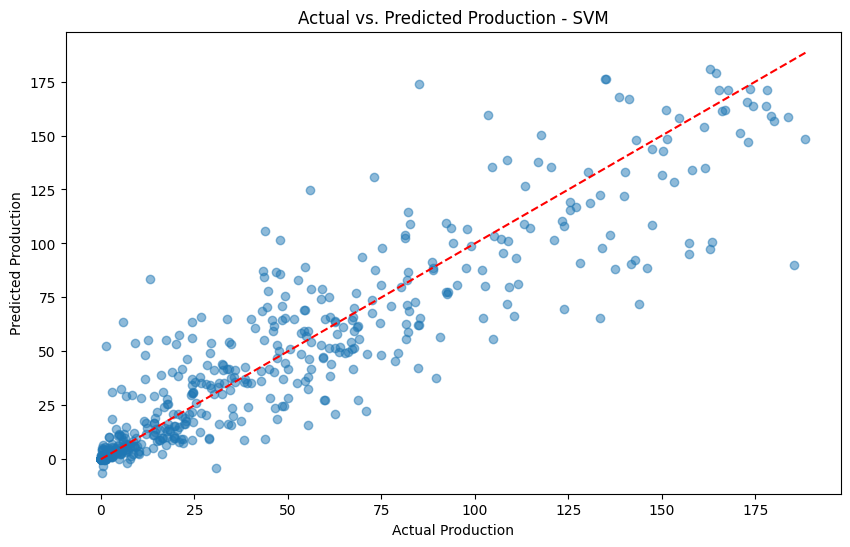

In [222]:
# Plot actual vs. predicted values for test data
plt.figure(figsize=(10, 6))
plt.scatter(y_test_cacak, y_power_pred_svm, alpha=0.5)
plt.xlabel('Actual Production')
plt.ylabel('Predicted Production')
plt.title('Actual vs. Predicted Production - SVM')
plt.plot([min(y_test_cacak), max(y_test_cacak)], [min(y_test_cacak), max(y_test_cacak)], color='red', linestyle='--')
plt.show()

## GRU

In [226]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from tensorflow.keras.optimizers import Adam

In [288]:
# Prepare the data
X = data_cacak[features].values
y = data_cacak[target_cacak].values

In [289]:
# Define the time window (e.g., 24 hours)
time_steps = 24

# Create sequences for each time window
def create_sequences(X, y, time_steps):
    sequences = []
    targets = []
    for i in range(len(X) - time_steps):
        sequences.append(X[i:i + time_steps])
        targets.append(y[i + time_steps])
    return np.array(sequences), np.array(targets)


In [290]:
X_sequences, y_sequences = create_sequences(X, y, time_steps)

In [305]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X_sequences, y_sequences, test_size=0.2, shuffle=False)

In [299]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense

# Define the model
def create_gru_model(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        GRU(50, return_sequences=True),
        GRU(25),
        Dense(1)
    ])
    #model.compile(optimizer='adam', loss='mean_squared_error')
    model.compile(loss='mean_squared_error', optimizer=Adam(learning_rate=0.001), metrics=['mae'])
    return model


In [300]:
input_shape = (time_steps, len(features))
model = create_gru_model(input_shape)

In [301]:
model.summary()

Model: "sequential_27"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru_14 (GRU)                         │ (None, 24, 50)              │           8,700 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_15 (GRU)                         │ (None, 25)                  │           5,775 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_61 (Dense)                     │ (None, 1)                   │              26 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,501 (56.64 KB)

 Trainable params: 14,501 (56.64 KB)

 Non-trainable params: 0 (0.00 B)

In [302]:
# Train the model
history_gru = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2)

Epoch 1/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - loss: 1822.7383 - mae: 20.9760 - val_loss: 5180.3735 - val_mae: 46.1638
Epoch 2/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - loss: 1583.3792 - mae: 17.9630 - val_loss: 4820.5542 - val_mae: 43.5077
Epoch 3/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 1369.7085 - mae: 16.4891 - val_loss: 4504.0918 - val_mae: 41.6898
Epoch 4/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 1378.3628 - mae: 16.2319 - val_loss: 4221.3247 - val_mae: 40.0931
Epoch 5/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 1227.1569 - mae: 15.0425 - val_loss: 3957.6550 - val_mae: 38.4399
Epoch 6/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - loss: 1080.3915 - mae: 13.8300 - val_loss: 3709.2664 - val_mae: 37.1879
Epoch 7/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - loss: 1041.6847 - mae: 13.3752 - val_loss: 3484.4944 - val_mae: 35.6097
Epoch 8/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 1079.8868 - mae: 13.5933 - val_loss: 3273.1550 - v

In [307]:
# Evaluate gru performance
y_power_pred_gru = model.predict(X_test)
r2_gru = r2_score(y_test, y_power_pred_gru)
mae_gru = mean_absolute_error(y_test, y_power_pred_gru)
rmse_gru = np.sqrt(mean_squared_error(y_test, y_power_pred_gru))
mse_gru = mean_squared_error(y_test, y_power_pred_gru)

print(f"GRU: R2: {r2_gru}, MAE: {mae_gru}, RMSE: {rmse_gru}, MSE: {mse_gru}")

52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
GRU: R2: 0.8817003101196412, MAE: 6.643713775068707, RMSE: 12.432355493214367, MSE: 154.56346310965742


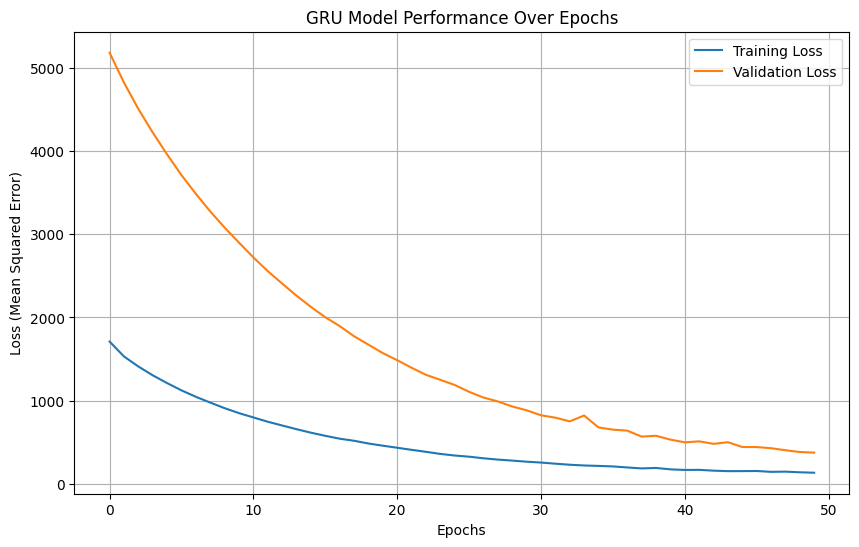

In [304]:
# Plot the training loss and validation loss
plt.figure(figsize=(10, 6))
plt.plot(history_gru.history['loss'], label='Training Loss')
plt.plot(history_gru.history['val_loss'], label='Validation Loss')

# Adding titles and labels
plt.title('GRU Model Performance Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (Mean Squared Error)')
plt.legend()
plt.grid(True)
plt.show()

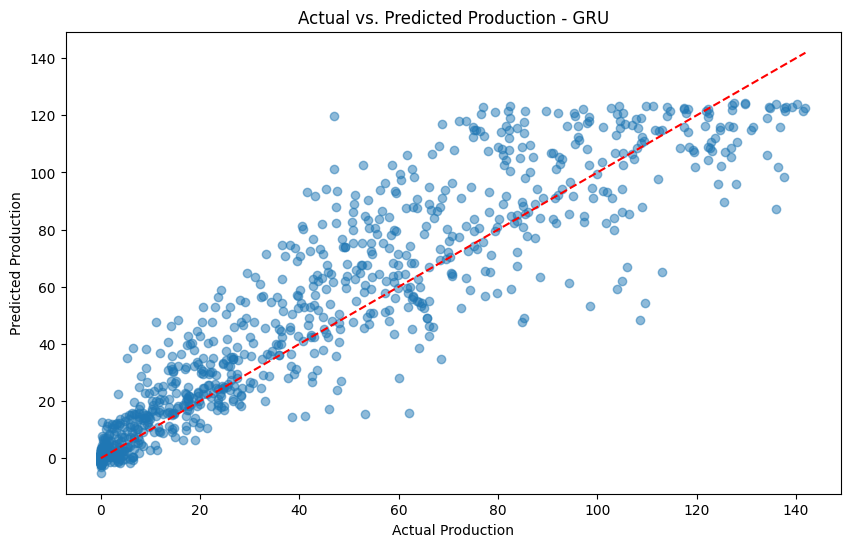

In [308]:
# Plot actual vs. predicted values for test data
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_power_pred_gru, alpha=0.5)
plt.xlabel('Actual Production')
plt.ylabel('Predicted Production')
plt.title('Actual vs. Predicted Production - GRU')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')
plt.show()

# Models (kraljevo data)

In [78]:
# Repeat for Kraljevo
X_train_kraljevo, X_test_kraljevo, y_train_kraljevo, y_test_kraljevo = train_test_split(X_kraljevo, y_kraljevo, test_size=0.2, random_state=42)


In [79]:
# Train ANN model for Kraljevo
ann_model_kraljevo = MLPRegressor(hidden_layer_sizes=(50,), max_iter=1000, random_state=42)
ann_model_kraljevo.fit(X_train_kraljevo, y_train_kraljevo)
ann_predictions_kraljevo = ann_model_kraljevo.predict(X_test_kraljevo)
print('ANN Model MSE (Kraljevo):', mean_squared_error(y_test_kraljevo, ann_predictions_kraljevo))


ANN Model MSE (Kraljevo): 9875.048577577147


In [80]:
# Train SVM model for Kraljevo
svm_model_kraljevo = SVR()
svm_model_kraljevo.fit(X_train_kraljevo, y_train_kraljevo)
svm_predictions_kraljevo = svm_model_kraljevo.predict(X_test_kraljevo)
print('SVM Model MSE (Kraljevo):', mean_squared_error(y_test_kraljevo, svm_predictions_kraljevo))

SVM Model MSE (Kraljevo): 19153.69997105708
